![Banner](images/09_distributed_spatial_datas.png)

# Rasterize, Zonal Statistics, Point Extraction and Polygonize at Scale

Most spatial analyses move between the two models of space: county averages of a climate raster,
covariate values at soil sampling points, a land cover map turned into field polygons, building
footprints burned onto a grid. With small data each of these is one function call. With a 21
billion pixel crop map and hundreds of zones, the raster no longer fits in memory and the work has
to be split into chunks that still give exact answers for zones and features that cross chunk
edges. This notebook uses `geolattice.distributed.bridge` for all four directions: zonal
statistics of the Great Plains covariates and of the 10 m Cropland Data Layer by county,
rasterizing counties and buildings, extracting all covariates at the 570 soil carbon points, and
polygonizing crop fields.

## Overview

### Four bridges between vectors and rasters

| Direction | Operation | Question it answers |
|---|---|---|
| vector to raster | **rasterize** | which zone (or how much of a feature) is in each pixel? |
| raster to vector, by zone | **zonal statistics** | what is the mean, sum or range of a raster inside each polygon? |
| raster to vector, by point | **point extraction** | what are the raster values at these locations? |
| raster to vector, by region | **polygonize** | which connected regions of equal value does the raster contain? |

### How each one is split into chunks

- **Rasterize**: each raster chunk needs only the features whose bounding boxes touch it (a
  spatial index query per chunk); chunks are burned independently.
- **Zonal statistics** is a reduction. Each chunk computes per-zone partial results (count, sum,
  sum of squares, minimum, maximum) for the zones it contains; adding the partials gives exact
  totals, means and standard deviations, however many chunks a zone spans.
- **Point extraction** reads only the chunks that hold points, and for bilinear interpolation the
  four neighbouring pixels (which may lie in a neighbouring chunk).
- **Polygonize** traces each chunk separately; regions cut by chunk seams are then merged with
  their same-valued neighbours across the seam.

### Pixel-centre rule

A pixel belongs to a polygon when its **centre** falls inside it (GDAL's default). Small or thin
polygons can therefore get no pixels at all; `all_touched=True` instead takes every pixel the
polygon touches, which overcounts along edges. For zonal statistics over counties (thousands of
pixels each) the choice hardly matters; for building footprints on a 10 m grid it matters a lot.

## Raster and Vector Bridges with GeoLattice

| Function | Inputs | Output | GPU |
|---|---|---|---|
| `pdist.rasterize(gdf, like, column=, all_touched=)` | features and a template raster | `(y, x)` DataArray on the template grid | polygons, opt-in (`compute="gpu"`) |
| `pdist.zonal_stats(zones, raster, stats=)` | polygons and a `(y, x)` or `(band, y, x)` raster | the zones with one column per statistic and band | partial statistics with CuPy |
| `pdist.extract_values(points, raster, method=)` | points and a raster | the points with one column per band | gathers on the GPU |
| `pdist.polygonize(raster, connectivity=)` | a `(y, x)` raster | GeoDataFrame of regions | CPU only |

All four accept lazy rasters and work chunk by chunk. `pdist.explain("bridge.rasterize")` shows
that `compute="auto"` keeps rasterize on the CPU: GDAL's scanline fill was faster than the GPU
kernel on typical inputs.

### Learning objectives

1. Name the four bridges between vector and raster data and how each is split into chunks.
2. Compute zonal statistics of several large rasters by county, on CPU and GPU, and check them
   against a direct calculation.
3. Summarize 21 billion 10 m CDL pixels by county without loading the raster.
4. Rasterize counties and buildings, and see the effect of the pixel-centre rule.
5. Extract 12 covariates at 570 sampling points, with nearest and bilinear interpolation.
6. Polygonize a crop map chunk by chunk and confirm the seam merging.

### Data

| Dataset | Content |
|---|---|
| Great Plains covariates | 90 m rasters, 17,196 x 15,245, EPSG:5070 |
| Great Plains counties | 225 polygons in Colorado, Kansas, New Mexico and Wyoming |
| Great Plains soil organic carbon | 570 sampling points with SOC (kg m-2) |
| 2025 CDL, 10 m | the Great Plains rectangle: 154,776 x 137,219 pixels (21 billion) |
| Kansas buildings | 1.6 million footprints (notebook 00) |

### Contents

- Setup
- Zonal statistics of three covariates by county
- Cropland of every county from 21 billion pixels
- Rasterizing counties and buildings
- Covariates at the soil carbon points
- Polygonizing crop fields
- Summary and exercises

## Setup

In [1]:
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings
import os  # environment and CPU count
import time  # wall-clock timing
from pathlib import Path  # file paths

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import pandas as pd  # tables
import geopandas as gpd  # vector data
import xarray as xr  # labelled rasters

import geolattice  # GeoLattice
import geolattice.distributed as pdist  # distributed and GPU spatial computing
import dist_data as dd  # chapter helper: paths, cached downloads, timers

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
pd.set_option("display.width", 140)  # wider printed tables
OUT = Path("outputs")  # results and scratch files written by this chapter
OUT.mkdir(exist_ok=True)  # create it if needed
caps = pdist.capabilities()  # engines and GPUs on this machine
print("GeoLattice", geolattice.__version__, "|", os.cpu_count(), "CPU cores |", caps["gpus"], "GPU(s)",  # versions
      f"({caps.get('gpu_memory_total', 0) / 1e9:.0f} GB)" if caps["gpus"] else "")  # GPU memory

import dask  # Dask configuration


def sync():  # wait for queued GPU work so timings are real
    if caps["gpus"]:  # only with a GPU
        import cupy as cp  # GPU arrays
        cp.cuda.Device().synchronize()  # block until done


counties = dd.gp_counties()  # 225 county polygons, EPSG:5070
print(len(counties), "counties in", sorted(counties.state.unique()))  # zones

GeoLattice 0.3.49 | 24 CPU cores | 1 GPU(s) (17 GB)
225 counties in ['CO', 'KS', 'NM', 'WY']


## Zonal statistics of three covariates by county

NDVI, mean annual precipitation and slope are stacked into one lazy `(band, y, x)` raster, and
`pdist.zonal_stats` returns the count, mean, minimum, maximum and standard deviation of each band
in every county.

In [2]:
stack = dd.gp_stack(["ndvi", "preci", "slope"])  # lazy (3, y, x), 2048 x 2048 chunks
print(dict(stack.sizes), stack.data.npartitions, "chunks |", dd.gb(stack.nbytes))  # size
res = {}  # timings
for c in (["cpu", "gpu"] if caps["gpus"] else ["cpu"]):  # both targets
    t0 = time.perf_counter()  # start
    zs = pdist.zonal_stats(counties, stack, stats=["count", "mean", "min", "max", "std"], compute=c)  # one pass over the stack
    res[c] = time.perf_counter() - t0; out = zs if c == "cpu" else out  # keep the CPU table
    print(f"compute={c}: {res[c]:.1f} s")  # time
if caps["gpus"]:  # compare the two
    cols = [k for k in zs.columns if k.startswith(("mean", "std"))]  # numeric columns
    print("largest |GPU - CPU| difference in means and standard deviations:", float(np.nanmax(np.abs(zs[cols].values - out[cols].values))))  # agreement
out[["county", "state", "count_ndvi", "mean_ndvi", "mean_preci", "mean_slope", "max_slope"]].head()  # first rows

{'band': 3, 'y': 17196, 'x': 15245} 216 chunks | 3.15 GB


compute=cpu: 6.4 s


compute=gpu: 3.8 s
largest |GPU - CPU| difference in means and standard deviations: 7.058455153696741e-09


,county,state,count_ndvi,mean_ndvi,mean_preci,mean_slope,max_slope
0,Los Alamos County,NM,32356,0.434753,526.603356,12.367376,59.610966
1,Pratt County,KS,222190,0.527103,693.357611,1.181373,7.868164
2,Decatur County,KS,274949,0.483210,554.580079,2.121339,13.056653
3,Cibola County,NM,1416265,0.279988,357.581973,4.518769,55.192734
4,Kiowa County,KS,222019,0.520429,645.634455,1.495461,15.402102


Both targets read the same 3.1 GB stack; the GPU version was somewhat faster because the
partial sums per chunk (a `bincount` over millions of pixels for every band) run on the device,
while reading the GeoTIFFs costs the same on both. As a check, the mean NDVI of three counties is recomputed directly: clip the
raster to each county with rioxarray and average the pixels whose centres fall inside.

In [3]:
ndvi = dd.gp_raster("ndvi")  # lazy NDVI
for i in [0, 1, 100]:  # three counties
    cty = counties.iloc[[i]]  # one county
    direct = float(ndvi.rio.clip(cty.geometry, all_touched=False).mean())  # pixels inside, directly
    print(f"{cty.county.iloc[0]:22s} zonal_stats {out.mean_ndvi.iloc[i]:.5f}   direct {direct:.5f}")  # compare

Los Alamos County      zonal_stats 0.43475   direct 0.43475


Pratt County           zonal_stats 0.52710   direct 0.52710


Sierra County          zonal_stats 0.24060   direct 0.24060


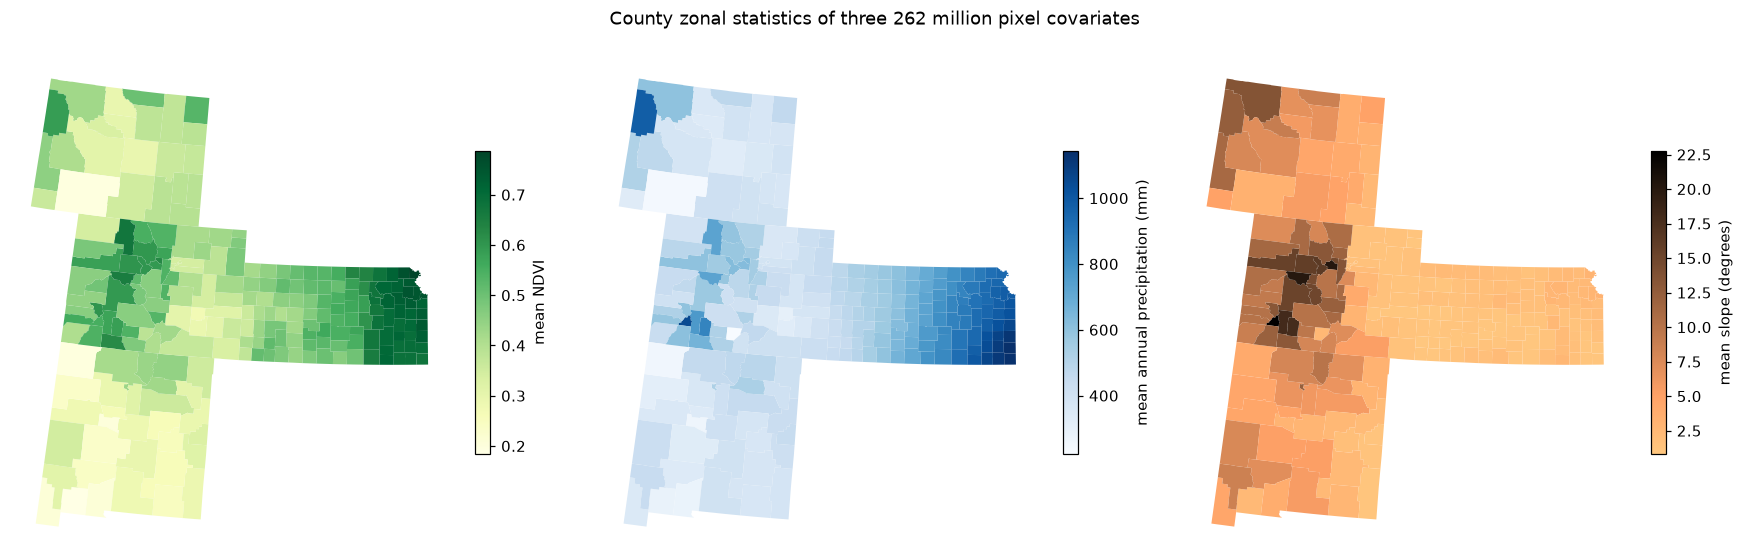

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(16, 5.2))  # three maps
for a, (col, cmap, label) in zip(ax, [("mean_ndvi", "YlGn", "mean NDVI"), ("mean_preci", "Blues", "mean annual precipitation (mm)"),  # columns
                                      ("mean_slope", "copper_r", "mean slope (degrees)")]):  # third
    out.plot(col, ax=a, cmap=cmap, legend=True, legend_kwds={"shrink": 0.6, "label": label})  # choropleth
    a.set_axis_off()  # no axes
plt.suptitle("County zonal statistics of three 262 million pixel covariates"); plt.tight_layout(); plt.show()  # draw

The direct check agrees to rounding. The maps show the east-to-west gradient of the Great Plains:
wetter, greener and flatter in eastern Kansas, drier and steeper towards the Rockies.

## Cropland of every county from 21 billion pixels

The same function works on the 10 m CDL. A lazy three-band raster flags, for every pixel, all
cropland, wheat and corn (1 or 0, NaN where there is no data); the `sum` statistic of each band is
then a pixel count per county, and 100 m2 per pixel turns it into area. Nothing larger than a few
chunks per thread is ever in memory, which makes the chunk size the memory control: each task
holds the uint8 codes, three float32 flag bands and the zone labels of one chunk, about a gigabyte
for 4096 x 4096 pixels. With 8192 pixel chunks the same job needed four times that per task, and
with 24 threads it exhausted this machine's 123 GB of memory while the notebook was written.

In [5]:
gp = counties.total_bounds  # extent of the counties
cdl = dd.cdl(chunks={"y": 4096, "x": 4096}).sel(x=slice(gp[0], gp[2]), y=slice(gp[3], gp[1]))  # lazy 10 m window, 4096 pixel chunks
print(f"{cdl.shape[0]:,} x {cdl.shape[1]:,} = {cdl.size / 1e9:.1f} billion pixels, {cdl.data.npartitions} chunks")  # size
luts = {}  # one lookup table per band
for band, groups in [("crop", dd.CROP_GROUPS), ("wheat", ["Wheat"]), ("corn", ["Corn"])]:  # three flags
    lut = np.zeros(256, np.float32)  # 0 for everything else
    for g in groups:  # the groups in this band
        lut[dd.CDL_GROUPS[g]] = 1.0  # 1 for their codes
    lut[0] = np.nan  # no data
    luts[band] = lut  # keep it
flags = xr.concat([pdist.raster.map_tiles(cdl, lambda b, xp, l=l: xp.asarray(l)[b], dtype="float32", compute="cpu")  # one band per flag
                   for l in luts.values()], dim="band").assign_coords(band=list(luts))  # (3, y, x)
with dd.PeakMemory() as pm:  # watch memory
    t0 = time.perf_counter()  # start
    crops = pdist.zonal_stats(counties, flags, stats=["count", "sum"], compute="cpu")  # one pass over 21 billion pixels
    secs = time.perf_counter() - t0  # elapsed
print(f"{secs / 60:.1f} minutes; peak process memory {pm.peak_gb:.1f} GB")  # cost
for band in luts:  # areas
    crops[f"{band}_km2"] = crops[f"sum_{band}"] * 100 / 1e6  # pixels to km2
crops["crop_share"] = crops.crop_km2 / (crops.count_crop * 100 / 1e6)  # share of mapped land
print(f"cropland in the 225 counties: {crops.crop_km2.sum():,.0f} km2, of which wheat {crops.wheat_km2.sum():,.0f} and corn {crops.corn_km2.sum():,.0f}")  # totals
crops.nlargest(5, "crop_km2")[["county", "state", "crop_km2", "wheat_km2", "corn_km2", "crop_share"]].round(2)  # top counties

154,776 x 137,219 = 21.2 billion pixels, 1330 chunks


6.3 minutes; peak process memory 27.1 GB
cropland in the 225 counties: 117,687 km2, of which wheat 33,105 and corn 33,861


,county,state,crop_km2,wheat_km2,corn_km2,crop_share
202,Washington County,CO,2227.32,1056.75,502.33,0.34
208,Kit Carson County,CO,2195.58,877.09,952.88,0.39
50,Sumner County,KS,2040.11,863.18,325.38,0.66
32,Thomas County,KS,1822.66,476.18,1114.27,0.66
216,Finney County,KS,1805.24,531.39,589.46,0.54


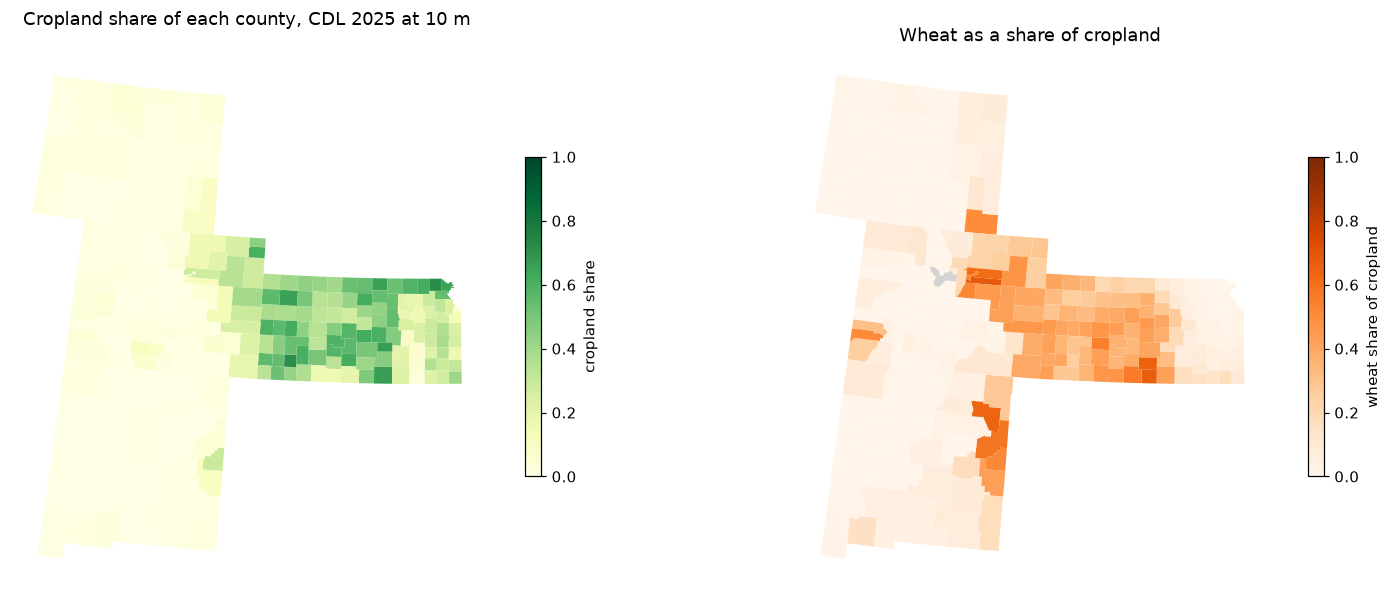

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))  # two maps
crops.plot("crop_share", ax=ax[0], cmap="YlGn", vmin=0, vmax=1, legend=True, legend_kwds={"shrink": 0.6, "label": "cropland share"})  # crop share
crops.assign(wheat_share=crops.wheat_km2 / crops.crop_km2.where(crops.crop_km2 > 0)).plot(  # wheat as a share of cropland
    "wheat_share", ax=ax[1], cmap="Oranges", vmin=0, vmax=1, legend=True, legend_kwds={"shrink": 0.6, "label": "wheat share of cropland"},
    missing_kwds={"color": "lightgrey"})  # counties without cropland
for a in ax:  # both maps
    a.set_axis_off()  # no axes
ax[0].set_title("Cropland share of each county, CDL 2025 at 10 m"); ax[1].set_title("Wheat as a share of cropland")  # titles
plt.tight_layout(); plt.show()  # draw

Kansas counties are 40 to 80 % cropland, and wheat makes up the largest share of it in central
Kansas and on the plains of eastern Colorado; the mountain and rangeland counties of Colorado,
Wyoming and New Mexico have little cropland at all.
The job decompressed and counted 21 billion pixels in about six minutes, and the process memory
stayed below 30 GB, a small fraction of the 254 GB the three flag bands would occupy in memory.

## Rasterizing counties and buildings

`pdist.rasterize` burns features onto the grid of a template raster. Counties onto the 90 m grid
give a zone raster (one number per county). Here the opt-in GPU kernel is timed against the
default GDAL scanline fill.

In [7]:
like = dd.gp_raster("elev")  # template grid, lazy
print(pdist.explain("bridge.rasterize")["reason"])  # why auto stays on the CPU
r = {}  # timings
for c in (["cpu", "gpu"] if caps["gpus"] else ["cpu"]):  # both targets
    t0 = time.perf_counter(); zone = pdist.rasterize(counties, like, values=np.arange(1, len(counties) + 1), dtype="int32", compute=c).compute(); sync()  # burn
    r[c] = time.perf_counter() - t0  # elapsed
    print(f"compute={c}: {r[c]:.2f} s, {int((zone > 0).sum()):,} pixels inside a county")  # result

GPU version is opt-in (slower on typical inputs); pass compute='gpu'


compute=cpu: 0.60 s, 129,746,588 pixels inside a county


compute=gpu: 0.63 s, 129,746,588 pixels inside a county


On this grid GDAL's scanline fill and the GPU kernel are close. GDAL fills each polygon row by
row, visiting only pixels inside it; the GPU kernel tests every pixel of a chunk against every
candidate polygon, which pays off only for many small polygons on fine grids.

Buildings are the opposite case: small polygons on a fine grid. Burned onto a 10 m grid of central
Wichita, the pixel-centre rule and `all_touched` give very different building areas.

13,645 buildings; footprint area 3.65 km2; pixel centre 3.67 km2; all touched 8.11 km2


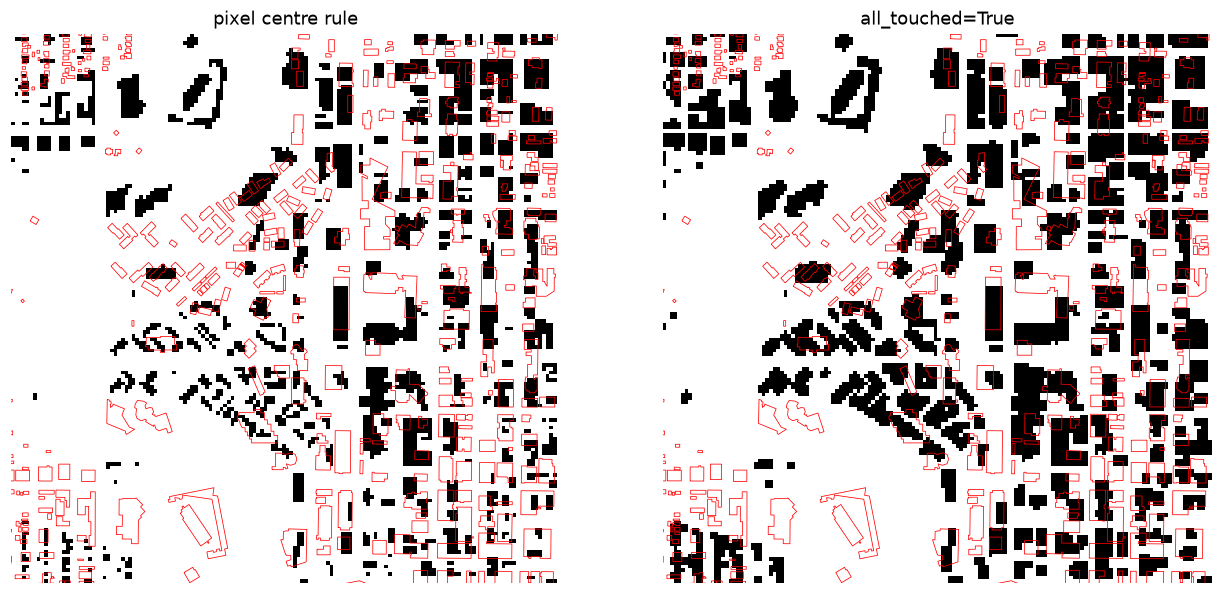

In [8]:
bld = dd.kansas_buildings()  # buildings, EPSG:4326
box = gpd.GeoSeries.from_xy([-97.34], [37.69], crs=4326).to_crs(5070).iloc[0]  # central Wichita
x0, y0 = box.x - 2500, box.y - 2500  # 5 x 5 km window
tmpl = xr.DataArray(np.zeros((500, 500), np.float32), dims=("y", "x"),  # a 10 m template grid
                    coords={"y": y0 + 5000 - 5 - 10 * np.arange(500), "x": x0 + 5 + 10 * np.arange(500)}).rio.write_crs(5070)  # pixel centres
win = pdist.vector.to_crs(bld, 5070).cx[x0:x0 + 5000, y0:y0 + 5000]  # buildings in the window
true_area = float(pdist.vector.clip(win, (x0, y0, x0 + 5000, y0 + 5000)).area.sum())  # footprint area inside
centre = pdist.rasterize(win, tmpl, dtype="uint8")  # pixel-centre rule
touched = pdist.rasterize(win, tmpl, all_touched=True, dtype="uint8")  # every touched pixel
print(f"{len(win):,} buildings; footprint area {true_area / 1e6:.2f} km2;",  # truth
      f"pixel centre {float(centre.sum()) * 100 / 1e6:.2f} km2; all touched {float(touched.sum()) * 100 / 1e6:.2f} km2")  # estimates
fig, ax = plt.subplots(1, 2, figsize=(12, 5.5))  # two panels
for a, arr, t in [(ax[0], centre, "pixel centre rule"), (ax[1], touched, "all_touched=True")]:  # both rules
    a.imshow(arr[150:300, 150:300], cmap="Greys", interpolation="nearest", extent=[x0 + 1500, x0 + 3000, y0 + 3500, y0 + 2000])  # 1.5 km zoom
    win.cx[x0 + 1500:x0 + 3000, y0 + 2000:y0 + 3500].boundary.plot(ax=a, color="r", lw=0.5)  # outlines
    a.set_xlim(x0 + 1500, x0 + 3000); a.set_ylim(y0 + 2000, y0 + 3500); a.set_title(t); a.set_axis_off()  # zoom
plt.tight_layout(); plt.show()  # draw

In total the pixel-centre rule came remarkably close to the true footprint area, while
`all_touched` more than doubled it. The total hides the errors of individual buildings: the zoom
shows small houses that got no pixel at all, and others that got a whole 10 x 10 m pixel for a
corner. The errors cancel over thousands of buildings but not for any single one. For building
or road coverage per pixel, compute the area fraction instead (for example by rasterizing onto a
grid ten times finer and coarsening), and never use `all_touched` for areas.

## Covariates at the soil carbon points

Regression kriging and machine learning (chapter 05 and notebook 09) start from a table of the
response and the covariates at each sampling point. `pdist.extract_values` reads, for 570 points,
only the chunks that contain them.

In [9]:
soc = dd.gp_points()  # 570 points with SOC
cov = dd.gp_stack()  # the 12 continuous covariates, lazy (12, y, x)
with dd.timer("nearest-pixel extraction of 12 covariates at 570 points"):  # read only needed chunks
    near = pdist.extract_values(soc, cov, method="nearest", name="v")  # one column per band
with dd.timer("bilinear extraction"):  # four pixels per point
    lin = pdist.extract_values(soc, cov, method="linear", name="v")  # interpolated
cols = [f"v_{b}" for b in dd.PREDICTORS]  # the new columns
table = near[["SiteID", "SOC"] + cols].rename(columns=lambda c: c[2:] if c.startswith("v_") else c)  # tidy names (strip the "v_" prefix only)
print(f"points with any missing covariate: {int(table[dd.PREDICTORS].isna().any(axis=1).sum())}")  # completeness
diff = (lin[cols] - near[cols]).abs().median().rename(lambda c: c[2:])  # typical change from nearest to bilinear
print("median |bilinear - nearest|:", diff.round(3).to_dict())  # by covariate
table.to_csv(OUT / "gp_soc_covariates.csv", index=False)  # saved for later notebooks
table.head()  # first rows

nearest-pixel extraction of 12 covariates at 570 points: 6.22 s


bilinear extraction: 24.81 s
points with any missing covariate: 9
median |bilinear - nearest|: {'elev': 0.648, 'slope': 0.263, 'aspect': 11.214, 'h_curvature': 0.009, 'v_curvature': 0.009, 'tpi_2000': 0.665, 'slopeleng': 0.211, 'ndvi': 0.001, 'preci': 0.0, 'temp': 0.0, 'silt_clay': 0.0, 'kfactor': 0.0}


,SiteID,SOC,elev,slope,aspect,h_curvature,v_curvature,tpi_2000,slopeleng,ndvi,preci,temp,silt_clay,kfactor
0,1,2.304,1544.0,0.790807,333.434937,0.014347,0.026692,1.153564,0.000000,0.282992,384.309204,9.775001,61.599998,0.32
1,2,3.154,2308.0,0.353674,0.000000,-0.000000,0.012345,-1.135742,0.147901,0.429635,195.019608,5.340000,34.799999,0.15
2,3,1.309,1715.0,1.767934,306.869904,0.035834,0.023493,3.805542,0.000000,0.399010,472.759064,9.979999,66.400002,0.37
3,4,4.717,1839.0,3.257900,12.528808,0.053657,-0.016244,12.818115,0.000000,0.382085,459.779114,9.384998,66.400002,0.37
4,5,2.230,1766.0,0.353674,90.000000,0.022987,-0.014048,10.004639,0.000000,0.311019,437.049103,9.509999,42.400002,0.20


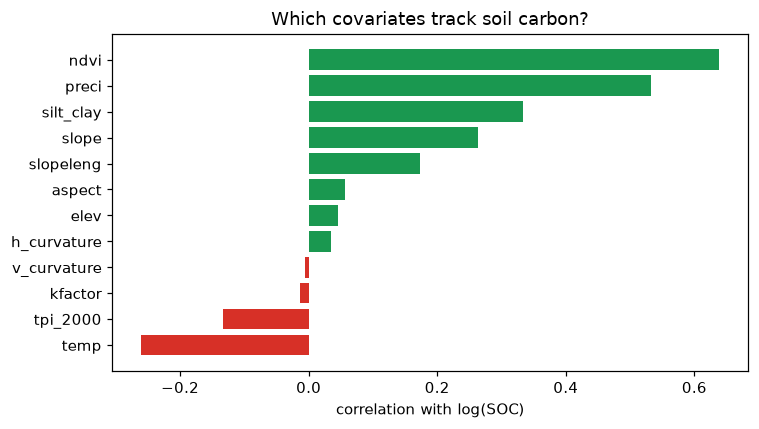

In [10]:
r = table[dd.PREDICTORS].corrwith(np.log(table.SOC)).sort_values()  # correlation with log SOC
fig, ax = plt.subplots(figsize=(7, 4))  # one panel
ax.barh(r.index, r.values, color=np.where(r > 0, "#1a9850", "#d73027"))  # bars
ax.set_xlabel("correlation with log(SOC)"); ax.set_title("Which covariates track soil carbon?")  # labels
plt.tight_layout(); plt.show()  # draw

Extraction took several seconds, and bilinear interpolation about four times as long, since it
gathers the four surrounding pixels in four passes. The 570 points are spread over the whole
region, so they touch most of the 2048 x 2048 chunks of all 12 layers, and every touched chunk is
read whole; extraction is fast for clustered points and for small chunks, and costs a full read of
the stack for points scattered everywhere. Soil
organic carbon rises with NDVI and precipitation and falls with temperature, the familiar
climate and vegetation controls; notebook 09 turns this table into a model and a map.

## Polygonizing crop fields

`pdist.polygonize` traces regions of equal value chunk by chunk and merges regions cut by chunk
seams. Polygonizing a 6 x 6 km CDL window south of Wichita with one chunk and with 16 chunks of
150 x 150 pixels should give the same polygons.

In [11]:
c = dd.cdl().sel(x=slice(box.x - 3000, box.x + 3000), y=slice(box.y - 9000, box.y - 15000)).compute()  # 600 x 600 pixels, 10 m
c = c.where(c > 0)  # no data as NaN
t0 = time.perf_counter(); one = pdist.polygonize(c, chunks=(600, 600)); t1 = time.perf_counter() - t0  # one chunk
t0 = time.perf_counter(); many = pdist.polygonize(c, chunks=(150, 150)); t16 = time.perf_counter() - t0  # 16 chunks with seams
print(f"one chunk: {len(one)} polygons ({t1:.2f} s) | 16 chunks: {len(many)} polygons ({t16:.2f} s)")  # counts
print(f"total area {one.area.sum() / 1e6:.3f} vs {many.area.sum() / 1e6:.3f} km2;",  # areas
      "same region areas:", bool(np.allclose(np.sort(one.area.values), np.sort(many.area.values))))  # identical regions

one chunk: 5281 polygons (0.12 s) | 16 chunks: 5281 polygons (0.28 s)
total area 36.000 vs 36.000 km2; same region areas: True


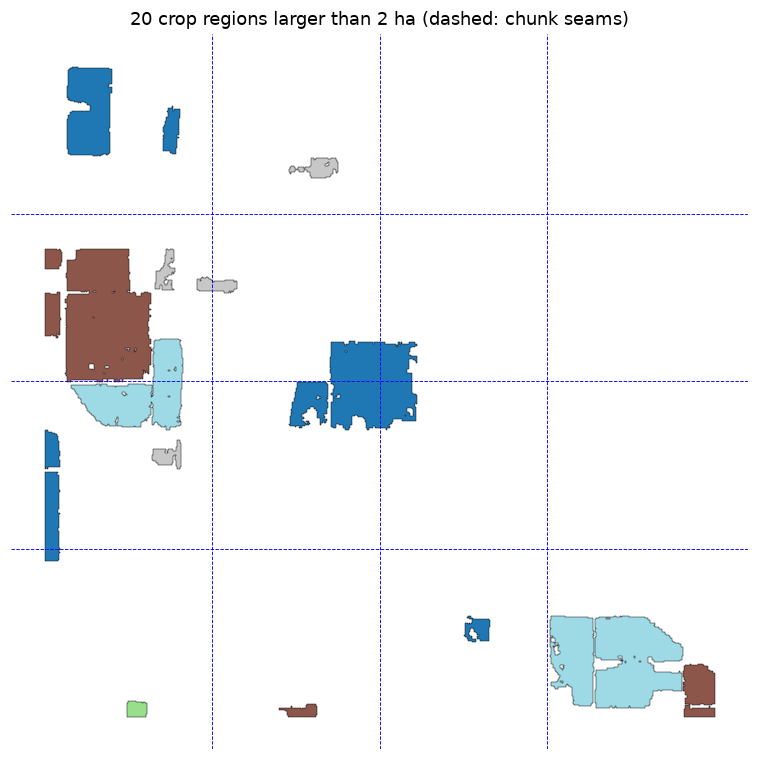

In [12]:
fields = many[many.value.isin(sum((dd.CDL_GROUPS[g] for g in dd.CROP_GROUPS), []))]  # crop regions only
fields = fields[fields.area > 2e4]  # larger than 2 ha
fig, ax = plt.subplots(figsize=(7, 7))  # one map
fields.plot(ax=ax, column="value", categorical=True, cmap="tab20", edgecolor="k", linewidth=0.3, legend=False)  # fields by crop code
for x in np.arange(1, 4) * 1500:  # chunk seams
    ax.axvline(box.x - 3000 + x, color="b", lw=0.6, ls="--"); ax.axhline(box.y - 15000 + x, color="b", lw=0.6, ls="--")  # dashed lines
ax.set_title(f"{len(fields)} crop regions larger than 2 ha (dashed: chunk seams)"); ax.set_axis_off(); plt.tight_layout(); plt.show()  # draw

The 16-chunk result contains the same regions as the single-chunk result: fields cut by the
dashed seams were stitched back together. CDL regions are not field boundaries in a cadastral
sense (neighbouring fields with the same crop merge, and classification noise creates small
fragments), but they are a useful first approximation, and the chunked algorithm makes it
possible to polygonize a whole state.

## Summary and exercises

- Rasterize, zonal statistics, point extraction and polygonize each split cleanly into chunks:
  per-chunk feature queries, per-chunk partial statistics, per-chunk gathers, and per-chunk
  tracing with seam merging.
- County statistics of three 262 million pixel covariates agreed with a direct clip-and-average,
  and the GPU matched the CPU.
- Counting cropland, wheat and corn in 225 counties from 21 billion 10 m pixels took about six
  minutes with less than 30 GB of memory; the chunk size controls that memory.
- The pixel-centre rule matched the total building area, though not single buildings;
  `all_touched` doubled it. For coverage fractions, rasterize finer and aggregate.
- Twelve covariates were extracted at 570 scattered points in seconds, and polygonizing with 16
  chunks gave the same regions as one chunk.

**Exercises**

1. Add `"std"` to the CDL zonal statistics. What does the standard deviation of a 0 or 1 flag
   mean?
2. Rasterize the Wichita buildings onto a 1 m grid and coarsen to 10 m to get a building fraction
   per pixel; compare its total with the true footprint area.
3. Extract the covariates with `method="linear"` and fit a linear model of log SOC on them. Does
   bilinear extraction improve the fit compared with nearest?
4. Polygonize the whole of Sedgwick County from the CDL with 2048 pixel chunks and count the corn
   and soybean fields.